# 04 · How Qwen turns text into a prediction, and what LoRA changed

Written for someone who has never worked with matrices inside a neural network.
Run the cells top to bottom. Each part builds on the one before.

| Part | What you learn |
|---|---|
| **A** | Vectors, matrices, and the one operation the whole model is built from |
| **B** | How text becomes numbers |
| **C** | One layer of Qwen, step by step, with the real weights |
| **D** | All 24 layers together, and how the prediction comes out |
| **E** | What LoRA is, in the same language |
| **F** | Which LoRA weights each of your specialists changed |

CPU is enough. Needs about 4 GB of RAM.

In [1]:
import sys, json, struct
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from safetensors import safe_open
from src.merge.merge import LazyWeights

BASE = "Qwen/Qwen2.5-0.5B-Instruct"     # HF id (read from your HF cache) or a local folder
SEED = 42
TASKS = ["gsm8k", "logic", "code"]
METHODS = ["avg", "task_arithmetic", "ties"]
MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
SPEC = {t: ROOT / f"checkpoints/specialists/{t}/seed{SEED}" for t in TASKS}
MERGED = {m: ROOT / f"checkpoints/merged/{m}" for m in METHODS}

# fixed colours: tasks always blue/orange/aqua, methods always yellow/magenta/green
C_TASK = dict(zip(TASKS, ["#2a78d6", "#eb6834", "#1baf7a"]))
C_METHOD = dict(zip(METHODS, ["#eda100", "#e87ba4", "#008300"]))
C_MOD = dict(zip(MODULES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))

torch.set_printoptions(precision=4, sci_mode=False, linewidth=150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e4e0", "axes.axisbelow": True})

def sub(module):
    return "self_attn" if module in MODULES[:4] else "mlp"

def wname(layer, module):
    return f"model.layers.{layer}.{sub(module)}.{module}.weight"

base = LazyWeights(BASE)
cfg = json.loads((base.path / "config.json").read_text())
N_LAYERS = cfg["num_hidden_layers"]
print("base folder:", base.path)

/mnt/EAD854DBD854A799/IITB Course/Sem 7/CS769 (Optimisation in Machine Learning)/Project (Does RL-induced reasoning survive merging)/Does_RL-induced_reasoning_survive_merging/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 632.67it/s]

base folder: /home/navya-garg/.cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots/7ae557604adf67be50417f59c2c2f167def9a775


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch.nn.functional as F
import matplotlib.patches as patches

hf = AutoModelForCausalLM.from_pretrained(base.path, dtype=torch.float32).eval()
c = hf.config
H, NH, NKV, FF, V = c.hidden_size, c.num_attention_heads, c.num_key_value_heads, c.intermediate_size, c.vocab_size
HD = H // NH
EPS = c.rms_norm_eps
THETA = getattr(c, "rope_theta", None) or (getattr(c, "rope_parameters", None) or {}).get("rope_theta", 10000.0)
try:
    tok = AutoTokenizer.from_pretrained(base.path)
    assert len(tok("hi").input_ids) > 0
except Exception:
    tok = None
    print("no tokenizer found: text cells will use made-up token ids")

def encode(text):
    if tok is None:
        return torch.tensor([[1, 5, 42, 7, 99, 3, 250, 8, 17, 64]]), [str(i) for i in [1, 5, 42, 7, 99, 3, 250, 8, 17, 64]]
    ids = tok(text, return_tensors="pt").input_ids
    return ids, [tok.decode([i]) for i in ids[0]]

def decode(i):
    return tok.decode([int(i)]) if tok else str(int(i))

def grid(ax, M, title="", fmt="{:.2f}", cmap="RdBu_r", labels=True):
    """Draw a small matrix with its numbers written in the cells."""
    M = torch.as_tensor(M).float()
    if M.dim() == 1: M = M[:, None]
    v = max(M.abs().max().item(), 1e-9)
    ax.imshow(M, cmap=cmap, vmin=-v, vmax=v)
    if labels:
        for (i, j), val in np.ndenumerate(M.numpy()):
            ax.text(j, i, fmt.format(val), ha="center", va="center", fontsize=9,
                    color="white" if abs(val) > 0.6 * v else "#23373b")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title, fontsize=10)

print(f"model: {N_LAYERS} layers | vector size {H} | {NH} query heads, {NKV} key/value heads of size {HD} | MLP size {FF} | vocabulary {V:,}")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 620.92it/s]


model: 24 layers | vector size 896 | 14 query heads, 2 key/value heads of size 64 | MLP size 4864 | vocabulary 151,936


---
# Part A · Vectors, matrices, and the one operation

## A1. The whole model in one sentence

The model is a long chain of **multiply-and-add** steps.
Text goes in as numbers. About 500 million fixed numbers (the **weights**) decide how the input numbers get mixed.
What comes out is one score per word in the vocabulary. The highest score is the model's guess for the next word.

Training (GRPO, LoRA) only ever changes those fixed numbers. Nothing else.

## A2. A vector is a list of numbers

Below, 4 numbers. In Qwen every token is described by a list of **896** numbers.

In [3]:
x = torch.tensor([1.0, 2.0, 0.5, -1.0])
print("x =", x.tolist(), "  length", len(x))

x = [1.0, 2.0, 0.5, -1.0]   length 4


## A3. A matrix is a grid of numbers, and it turns one vector into another

A matrix `W` with 3 rows and 4 columns takes a vector of 4 numbers and gives back a vector of 3 numbers.

**Each output number is a weighted sum of all the input numbers. Row `i` of `W` holds the weights for output `i`.**

```
            x =  [ 1.0   2.0   0.5  -1.0 ]

W row 0 = [ 0.5   0.0   1.0   0.0 ]  →  0.5·1.0 + 0.0·2.0 + 1.0·0.5 + 0.0·(−1.0) = 1.0
W row 1 = [ 0.0   1.0   0.0  -1.0 ]  →  0.0·1.0 + 1.0·2.0 + 0.0·0.5 + (−1.0)·(−1.0) = 3.0
W row 2 = [ 0.2   0.2   0.2   0.2 ]  →  0.2 · (1.0 + 2.0 + 0.5 − 1.0)          = 0.5
```

This is written `y = W x` (or `W @ x` in Python). That is the only real operation in the model.

by hand: [1.0, 3.0, 0.5000000596046448]
W @ x  : [1.0, 3.0, 0.5]


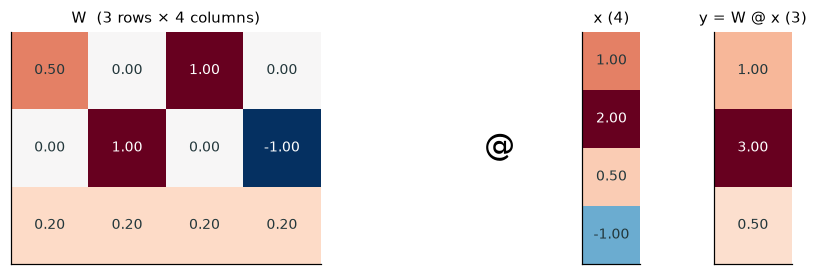

In [4]:
W = torch.tensor([[0.5, 0.0, 1.0,  0.0],
                  [0.0, 1.0, 0.0, -1.0],
                  [0.2, 0.2, 0.2,  0.2]])
by_hand = [sum(W[i, j] * x[j] for j in range(4)).item() for i in range(3)]
print("by hand:", by_hand)
print("W @ x  :", (W @ x).tolist())

fig, axes = plt.subplots(1, 4, figsize=(9, 2.6), gridspec_kw={"width_ratios": [4, 0.6, 1, 1]})
grid(axes[0], W, "W  (3 rows × 4 columns)")
axes[1].axis("off"); axes[1].text(0.5, 0.5, "@", fontsize=20, ha="center", va="center")
grid(axes[2], x, "x (4)")
grid(axes[3], W @ x, "y = W @ x (3)")
plt.tight_layout(); plt.show()

Read the picture: red = positive, blue = negative, white = zero.
Row 1 of `W` says "output 1 = input 1 minus input 3". The matrix *is* the rule.

## A4. A linear layer = matrix + bias

Neural networks call `y = W x + b` a **linear layer**. `b` is one extra number added to each output.

Two facts used everywhere below:
- PyTorch stores `W` as **[out, in]**: one row per output.
- Many tokens at once: stack them as rows of `X` (shape [T, in]) and compute `X @ W.T + b` → shape [T, out]. Same rule, applied to every token separately.

In [5]:
X = torch.tensor([[1.0, 2.0, 0.5, -1.0],      # token 0
                  [0.0, 1.0, 1.0,  1.0],      # token 1
                  [3.0, 0.0, 0.0,  0.0]])     # token 2
b = torch.tensor([0.1, 0.0, -0.5])
print("X @ W.T + b =\n", X @ W.T + b)
print("\nrow 0 is the same as before (+ bias):", (W @ X[0] + b).tolist())

X @ W.T + b =
 tensor([[1.1000, 3.0000, 0.0000],
        [1.1000, 0.0000, 0.1000],
        [1.6000, 0.0000, 0.1000]])

row 0 is the same as before (+ bias): [1.100000023841858, 3.0, 0.0]


## A5. The same thing at full size

In Qwen, `q_proj` in layer 0 is a matrix of shape **[896, 896]**: 802,816 weights.
Each of its 896 outputs is a weighted sum of 896 inputs.

Below: take one real token vector, compute one output number, and see which of the 896 inputs pushed it up or down most.
Each bar is one product `W[i, j] · input[j]`. The output is just their sum (plus the bias).

output 0 = sum of 896 products + bias = 0.1481 + -0.0150 = 0.1332
PyTorch gives                                       0.1332


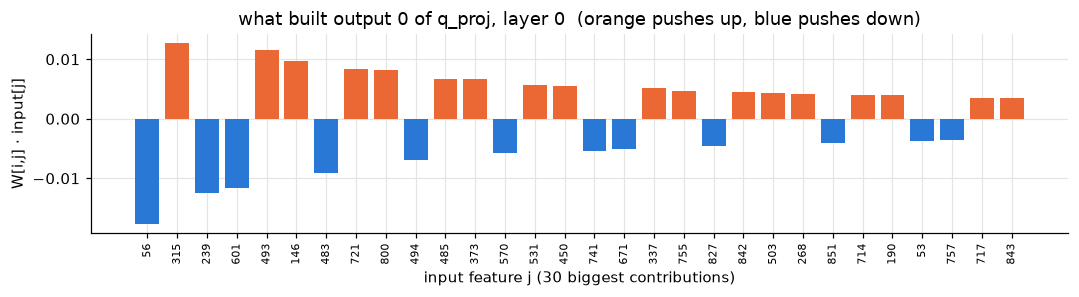

In [6]:
ids, toks = encode("The knight always tells the truth.")
with torch.no_grad():
    vec = hf.model.layers[0].input_layernorm(hf.model.embed_tokens(ids))[0, -1]   # one real 896-number vector
Wq = base.get(wname(0, "q_proj")).float()
bq = base.get(wname(0, "q_proj").replace("weight", "bias")).float()
i = 0
products = Wq[i] * vec
print(f"output {i} = sum of {len(products)} products + bias = {products.sum().item():.4f} + {bq[i].item():.4f} = {(products.sum() + bq[i]).item():.4f}")
print(f"PyTorch gives                                       {(vec @ Wq.T + bq)[i].item():.4f}")

order = products.abs().argsort(descending=True)[:30]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(30), products[order], color=["#eb6834" if p > 0 else "#2a78d6" for p in products[order]])
ax.set_xticks(range(30), [str(int(j)) for j in order], rotation=90, fontsize=7)
ax.set_xlabel("input feature j (30 biggest contributions)"); ax.set_ylabel("W[i,j] · input[j]")
ax.set_title(f"what built output {i} of q_proj, layer 0  (orange pushes up, blue pushes down)")
plt.tight_layout(); plt.show()

---
# Part B · From text to numbers

## B1. Tokens

The tokenizer chops text into pieces (**tokens**) and gives each piece a number (its **id**) from a fixed list of 151,936 pieces.
A token is often a word, part of a word, or a word with its leading space.

In [7]:
TEXT = "Alice says Bob is a knave. Bob says Alice is a knight. So the knight is"
ids, toks = encode(TEXT)
T = ids.shape[1]
for i_, t_ in zip(ids[0].tolist(), toks):
    print(f"{i_:>7}  {t_!r}")
print("T =", T, "tokens")

  61686  'Alice'
   2727  ' says'
  14261  ' Bob'
    374  ' is'
    264  ' a'
   1148  ' kn'
    523  'ave'
     13  '.'
  14261  ' Bob'
   2727  ' says'
  29405  ' Alice'
    374  ' is'
    264  ' a'
  46609  ' knight'
     13  '.'
   2055  ' So'
    279  ' the'
  46609  ' knight'
    374  ' is'
T = 19 tokens


## B2. Embedding: one row per token

`embed_tokens` is a table of shape **[151936, 896]**. Row `k` is the starting vector for token id `k`.
Turning ids into vectors is a **lookup**, not a multiplication: just pick the rows.

(It is the same as multiplying a "one-hot" vector, all zeros except a 1 at position `k`, by the table. The check below shows that.)

embedding table: (151936, 896)
row lookup == one-hot @ table: True

first 10 of the 896 numbers for token ' says':
tensor([ 0.0047, -0.0002, -0.0084,  0.0105,  0.0165,  0.0199, -0.0284,  0.0192, -0.0061,  0.0094])


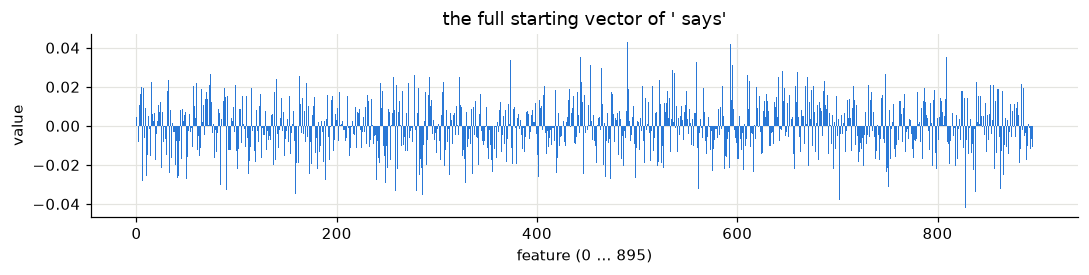

In [8]:
E = base.get("model.embed_tokens.weight").float()
print("embedding table:", tuple(E.shape))
k = int(ids[0, 1])
onehot = torch.zeros(E.shape[0]); onehot[k] = 1
print(f"row lookup == one-hot @ table: {torch.equal(E[k], onehot @ E)}")
print(f"\nfirst 10 of the {E.shape[1]} numbers for token {toks[1]!r}:\n{E[k, :10]}")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.bar(range(E.shape[1]), E[k], color="#2a78d6", width=1.0)
ax.set_xlabel("feature (0 … 895)"); ax.set_ylabel("value"); ax.set_title(f"the full starting vector of {toks[1]!r}")
plt.tight_layout(); plt.show()

These 896 numbers mean nothing one by one. What matters is how vectors relate to each other.
Words used in similar ways end up with similar vectors. **Cosine similarity** measures that: 1 = same direction, 0 = unrelated.

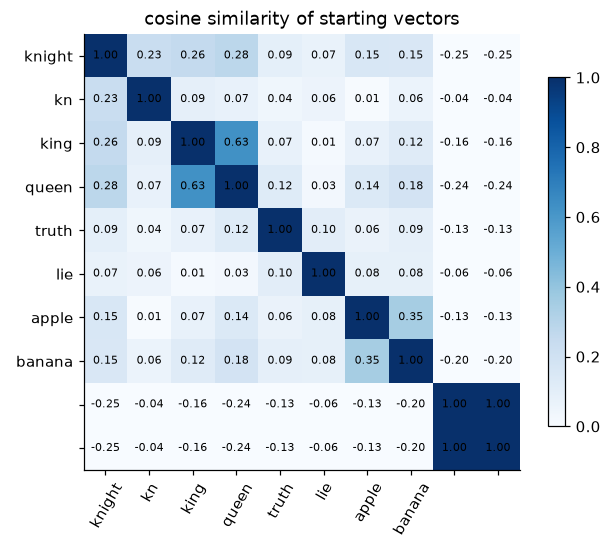

In [9]:
words = [" knight", " knave", " king", " queen", " truth", " lie", " apple", " banana", " 7", " 8"]
if tok is not None:
    wid = [tok(w).input_ids[0] for w in words]
    vecs = F.normalize(E[wid], dim=-1)
    sim = vecs @ vecs.T
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(words)), [tok.decode([w]) for w in wid], rotation=60)
    ax.set_yticks(range(len(words)), [tok.decode([w]) for w in wid]); ax.grid(False)
    for (r_, c_), v_ in np.ndenumerate(sim.numpy()):
        ax.text(c_, r_, f"{v_:.2f}", ha="center", va="center", fontsize=7)
    plt.colorbar(im, shrink=0.8); ax.set_title("cosine similarity of starting vectors")
    plt.tight_layout(); plt.show()
else:
    print("needs the tokenizer")

## B3. The big picture: the residual stream

From here on each token is a vector of 896 numbers. Call the stack of them `x`, shape [T, 896].
`x` flows down through 24 layers. **Each layer reads `x` and adds something to it.** Nothing is overwritten.
This running vector is called the **residual stream**.

```
 "Alice says Bob ... is"                 text
        │ tokenizer
        ▼
 [ 44045, 2727, ... ]                    T token ids
        │ embed_tokens: pick row k from a 151,936 × 896 table
        ▼
 x  (T × 896)                            one vector per token
        │
        │──► layer 0 :  x = x + attention(x) ;  x = x + mlp(x)
        │──► layer 1 :  same recipe, different weights
        │      ...
        │──► layer 23
        ▼
 final RMSNorm
        │ multiply by embed_tokensᵀ   (896 → 151,936)
        ▼
 scores  (T × 151,936)                   one score for every possible next token
        │ softmax on the LAST token's row
        ▼
 probabilities  →  " knight" 41%, " Bob" 12%, ...
```

Every layer has the **same shape** and the **same recipe**. Only the weight numbers differ.

---
# Part C · One layer, step by step

The full recipe for one layer. The **7 boxed matrices** are the ones LoRA trains.

```
 x  (T × 896) ─────────────────────────────────────────┐  keep a copy
    │                                                  │
    ▼                                                  │
 RMSNorm (scale g₁)                    → a  (T × 896)  │
    │                                                  │
    ├──► [ q_proj ] 896 → 896          → Q             │
    ├──► [ k_proj ] 896 → 128          → K             │   ATTENTION
    └──► [ v_proj ] 896 → 128          → V             │   tokens look at
         rotate Q, K by position (RoPE)                │   earlier tokens
         scores = Q · Kᵀ / 8, hide future → softmax → P│
         O = P · V                     → O  (T × 896)  │
              │                                        │
         [ o_proj ] 896 → 896          → attn          │
              ▼                                        │
             (+) ◄─────────────────────────────────────┘
              │  x  ───────────────────────────────────┐  keep a copy
              ▼                                        │
         RMSNorm (scale g₂)            → m             │
              │                                        │
       ┌──────┴───────┐                                │   MLP
  [ gate_proj ]   [ up_proj ]   896 → 4864             │   each token on
       │ G            │ U                              │   its own
    silu(G)    ×      U   (number by number)           │
              │                                        │
         [ down_proj ] 4864 → 896      → mlp           │
              ▼                                        │
             (+) ◄─────────────────────────────────────┘
              │
         x for the next layer
```

We now run each box with the real weights of layer 0, on the real sentence.

In [10]:
L = 0
P_ = f"model.layers.{L}."
Wt = lambda name: base.get(P_ + name).float()
with torch.no_grad():
    x0 = hf.model.embed_tokens(ids)[0]
print("x going into layer 0:", tuple(x0.shape), " (T tokens × 896 numbers)")

x going into layer 0: (19, 896)  (T tokens × 896 numbers)


## C1. RMSNorm: put every vector on the same scale

Some vectors are large, some small. Before each block, every token vector is divided by its own typical size
(root-mean-square), then each of the 896 features is multiplied by a learned scale `g`.

`a = x / sqrt(mean(x²)) · g`

`g` is a vector of 896 weights. It is **not** one of LoRA's 7 matrices, so LoRA never changes it.

In [11]:
def rmsnorm(x, g):
    return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + EPS) * g

g1 = Wt("input_layernorm.weight")
a = rmsnorm(x0, g1)
for t_ in range(min(3, T)):
    print(f"token {toks[t_]!r:<10} size before {x0[t_].pow(2).mean().sqrt():.4f}  →  after dividing {rmsnorm(x0, torch.ones(H))[t_].pow(2).mean().sqrt():.4f}")
print("\ng (first 10 of {H}):", g1[:10])

token 'Alice'    size before 0.0138  →  after dividing 0.9974
token ' says'    size before 0.0132  →  after dividing 0.9971
token ' Bob'     size before 0.0126  →  after dividing 0.9968

g (first 10 of {H}): tensor([-0.0469,  0.0444, -0.0254,  0.0845, -0.0437,  0.0391, -0.0417, -0.0267, -0.1060, -0.0310])


## C2. Attention: let tokens look at earlier tokens

On its own a token vector knows only its own word. To understand "the knight is", the last token must collect information from earlier ones.
Attention does that in four moves.

**Move 1. Make three new vectors per token, with three matrices.**
- `Q = a @ W_qᵀ + b_q` (**query**): what this token is looking for
- `K = a @ W_kᵀ + b_k` (**key**): what this token offers, as a label
- `V = a @ W_vᵀ + b_v` (**value**): what this token hands over if chosen

**Move 2. Score every pair.** score(t, s) = Q[t] · K[s] (multiply matching numbers, add them up). High = good match.

**Move 3. Softmax.** Turn each row of scores into percentages that add up to 100%. A token may only look at itself and earlier tokens, so future scores are set to −∞ (0%).

**Move 4. Weighted average.** Output for token t = Σₛ P[t, s] · V[s].

A tiny version first: 3 tokens, vectors of size 2.

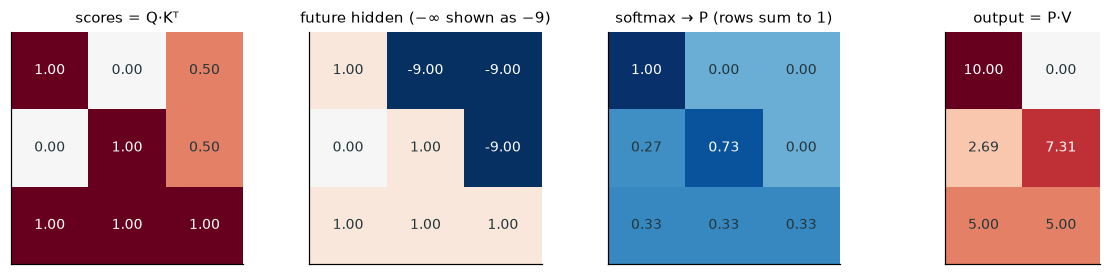

token 2 output = P[2,0]·V[0] + P[2,1]·V[1] + P[2,2]·V[2] = [5.0, 5.0]


In [12]:
Qt = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
Kt = torch.tensor([[1.0, 0.0], [0.0, 1.0], [0.5, 0.5]])
Vt = torch.tensor([[10.0, 0.0], [0.0, 10.0], [5.0, 5.0]])
S = Qt @ Kt.T
S_masked = S.masked_fill(torch.ones(3, 3, dtype=torch.bool).triu(1), float("-inf"))
Pt = S_masked.softmax(-1)
Ot = Pt @ Vt
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6))
grid(axes[0], S, "scores = Q·Kᵀ")
grid(axes[1], S_masked.clamp(min=-9), "future hidden (−∞ shown as −9)")
grid(axes[2], Pt, "softmax → P (rows sum to 1)", cmap="Blues")
grid(axes[3], Ot, "output = P·V")
plt.tight_layout(); plt.show()
print("token 2 output = P[2,0]·V[0] + P[2,1]·V[1] + P[2,2]·V[2] =", Ot[2].tolist())

**Heads.** Qwen does this 14 times in parallel. `Q` (896 numbers) is cut into 14 pieces of 64, one per **head**.
Each head can look for something different.
`K` and `V` only have 128 numbers = 2 pieces of 64. Each K/V piece is shared by 7 query heads.
This saving is called grouped-query attention. It is why `k_proj` and `v_proj` are only 128 × 896.

**Position (RoPE).** Q·K alone does not know word order. Before scoring, each pair of numbers in Q and K is rotated
by an angle that grows with the token's position. Tokens far apart end up rotated differently, which changes their score.
No weights are involved.

Now the real thing.

In [13]:
Wq, bq = Wt("self_attn.q_proj.weight"), Wt("self_attn.q_proj.bias")
Wk, bk = Wt("self_attn.k_proj.weight"), Wt("self_attn.k_proj.bias")
Wv, bv = Wt("self_attn.v_proj.weight"), Wt("self_attn.v_proj.bias")
print(f"q_proj W {tuple(Wq.shape)}   k_proj W {tuple(Wk.shape)}   v_proj W {tuple(Wv.shape)}")
Q = a @ Wq.T + bq
K = a @ Wk.T + bk
Vv = a @ Wv.T + bv
print(f"Q {tuple(Q.shape)}   K {tuple(K.shape)}   V {tuple(Vv.shape)}")

def rope(z):                                     # z: [heads, T, HD]
    inv = 1.0 / THETA ** (torch.arange(0, HD, 2).float() / HD)
    ang = torch.outer(torch.arange(z.shape[1]).float(), inv)
    ang = torch.cat([ang, ang], -1)
    z1, z2 = z[..., :HD // 2], z[..., HD // 2:]
    return z * ang.cos() + torch.cat([-z2, z1], -1) * ang.sin()

Qh = rope(Q.view(T, NH, HD).transpose(0, 1))                                   # [14, T, 64]
Kh = rope(K.view(T, NKV, HD).transpose(0, 1)).repeat_interleave(NH // NKV, 0)  # share K/V heads
Vh = Vv.view(T, NKV, HD).transpose(0, 1).repeat_interleave(NH // NKV, 0)
scores = Qh @ Kh.transpose(-1, -2) / HD ** 0.5
scores = scores.masked_fill(torch.ones(T, T, dtype=torch.bool).triu(1), float("-inf"))
P = scores.softmax(-1)                                                         # [14, T, T]
O = (P @ Vh).transpose(0, 1).reshape(T, H)                                     # heads glued back: [T, 896]
print(f"per-head Q {tuple(Qh.shape)}   attention P {tuple(P.shape)}   O {tuple(O.shape)}")

q_proj W (896, 896)   k_proj W (128, 896)   v_proj W (128, 896)
Q (19, 896)   K (19, 128)   V (19, 128)
per-head Q (14, 19, 64)   attention P (14, 19, 19)   O (19, 896)


Each square below is one head. Row = the token doing the looking, column = the token being looked at.
Darker = more attention. Heads in layer 0 often look at the first token or at the previous token.

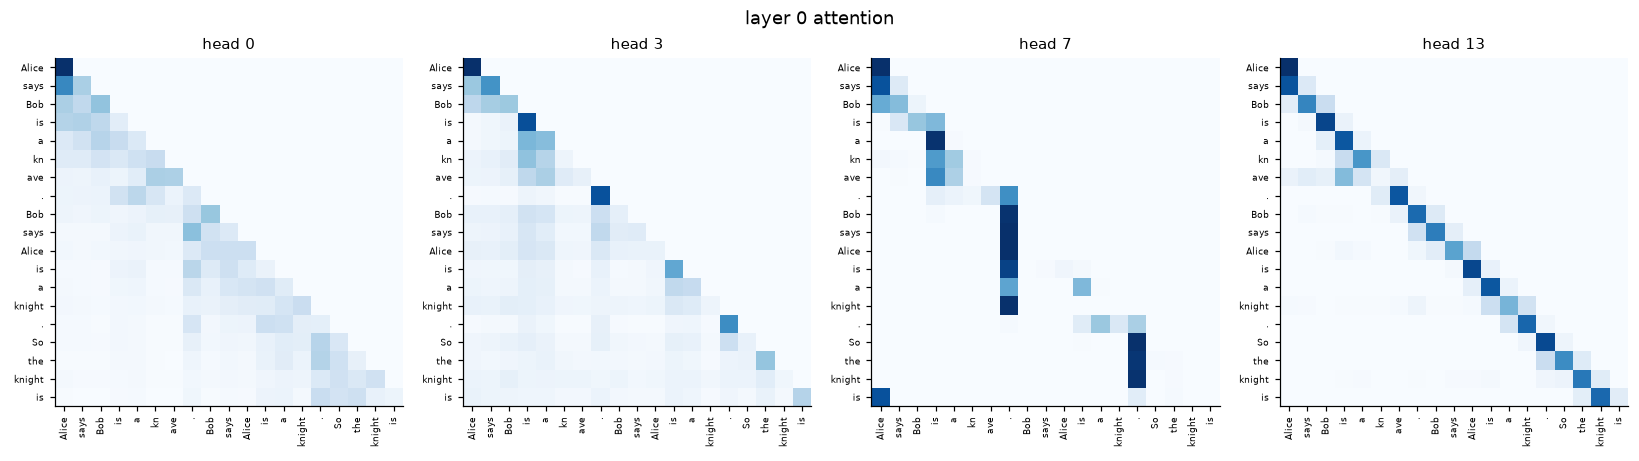

head 0: the last token ' is' spreads its attention as:
    23.3%  →  '.'
    21.1%  →  ' the'
    18.4%  →  ' So'
     7.4%  →  ' knight'
     6.0%  →  ' a'


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, h_ in zip(axes, [0, NH // 4, NH // 2, NH - 1]):
    ax.imshow(P[h_], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(T), toks, rotation=90, fontsize=6); ax.set_yticks(range(T), toks, fontsize=6)
    ax.set_title(f"head {h_}", fontsize=10); ax.grid(False)
plt.suptitle(f"layer {L} attention"); plt.tight_layout(); plt.show()

h_ = 0
print(f"head {h_}: the last token {toks[-1]!r} spreads its attention as:")
for s_ in P[h_, -1].argsort(descending=True)[:5]:
    print(f"   {P[h_, -1, s_].item():6.1%}  →  {toks[s_]!r}")

## C3. `o_proj`, then add to the stream

`O` is 14 head outputs glued side by side. `o_proj` (896 × 896) mixes them into one vector per token.
That result is **added** to `x`.

In [15]:
Wo = Wt("self_attn.o_proj.weight")
attn = O @ Wo.T
x1 = x0 + attn
print(f"o_proj W {tuple(Wo.shape)}   attn {tuple(attn.shape)}")
print(f"size of what attention added vs size of x:  {attn.norm().item():.3f} vs {x0.norm().item():.3f}")

o_proj W (896, 896)   attn (19, 896)
size of what attention added vs size of x:  1.702 vs 1.834


## C4. MLP: each token thinks on its own

No mixing between tokens here. Each token vector, by itself:

1. RMSNorm again (scale `g₂`) → `m`
2. Two matrices blow it up from 896 to **4864** numbers: `G = m @ W_gateᵀ`, `U = m @ W_upᵀ`
3. `silu(G)` acts as a soft on/off switch for each of the 4864 slots. Multiply by `U` number by number.
4. `down_proj` squeezes 4864 back to 896 → added to `x`.

Each of the 4864 slots is often called a **neuron**. A neuron that fires strongly writes its column of `down_proj` into the stream.

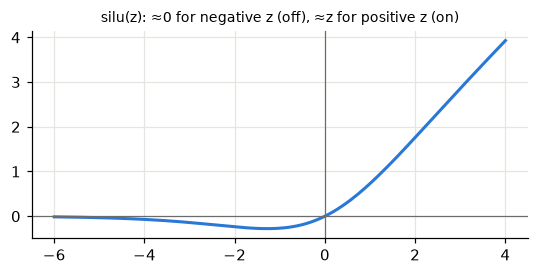

In [16]:
zz = torch.linspace(-6, 4, 200)
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(zz, F.silu(zz), color="#2a78d6", lw=2)
ax.axhline(0, color="#6b6b6b", lw=0.8); ax.axvline(0, color="#6b6b6b", lw=0.8)
ax.set_title("silu(z): ≈0 for negative z (off), ≈z for positive z (on)", fontsize=9)
plt.tight_layout(); plt.show()

gate W (4864, 896)  up W (4864, 896)  down W (896, 4864)
m (19, 896) → G, U (19, 4864) → act (19, 4864) → mlp (19, 896)


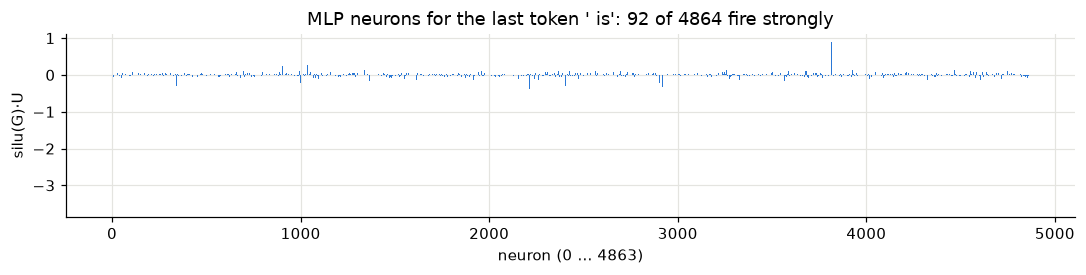

In [17]:
g2 = Wt("post_attention_layernorm.weight")
Wg, Wu, Wd = Wt("mlp.gate_proj.weight"), Wt("mlp.up_proj.weight"), Wt("mlp.down_proj.weight")
m = rmsnorm(x1, g2)
G = m @ Wg.T
U = m @ Wu.T
act = F.silu(G) * U
mlp = act @ Wd.T
x2 = x1 + mlp
print(f"gate W {tuple(Wg.shape)}  up W {tuple(Wu.shape)}  down W {tuple(Wd.shape)}")
print(f"m {tuple(m.shape)} → G, U {tuple(G.shape)} → act {tuple(act.shape)} → mlp {tuple(mlp.shape)}")

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.bar(range(FF), act[-1], color="#2a78d6", width=1.0)
ax.set_xlabel(f"neuron (0 … {FF - 1})"); ax.set_ylabel("silu(G)·U")
strong = (act[-1].abs() > act[-1].abs().mean() * 5).sum().item()
ax.set_title(f"MLP neurons for the last token {toks[-1]!r}: {strong} of {FF} fire strongly")
plt.tight_layout(); plt.show()

## C5. Check: is this really what Qwen computes?

Put all the steps into one function and compare with Hugging Face's own output for layer 0.
If the difference is ~1e-6 or smaller, the recipe above is the complete layer.

In [18]:
def layer(x, W, l, trace=None):
    """One Qwen2 layer from raw matrices. W(name) returns the float32 tensor with that name."""
    p = f"model.layers.{l}."
    t = {} if trace is None else trace
    T_ = x.shape[0]
    t["a"] = a_ = rmsnorm(x, W(p + "input_layernorm.weight"))
    t["Q"] = q = a_ @ W(p + "self_attn.q_proj.weight").T + W(p + "self_attn.q_proj.bias")
    t["K"] = k = a_ @ W(p + "self_attn.k_proj.weight").T + W(p + "self_attn.k_proj.bias")
    t["V"] = v = a_ @ W(p + "self_attn.v_proj.weight").T + W(p + "self_attn.v_proj.bias")
    q = rope(q.view(T_, NH, HD).transpose(0, 1))
    k = rope(k.view(T_, NKV, HD).transpose(0, 1)).repeat_interleave(NH // NKV, 0)
    v = v.view(T_, NKV, HD).transpose(0, 1).repeat_interleave(NH // NKV, 0)
    s_ = (q @ k.transpose(-1, -2) / HD ** 0.5).masked_fill(torch.ones(T_, T_, dtype=torch.bool).triu(1), float("-inf"))
    t["P"] = P_ = s_.softmax(-1)
    t["attn"] = at = (P_ @ v).transpose(0, 1).reshape(T_, NH * HD) @ W(p + "self_attn.o_proj.weight").T
    x = x + at
    t["m"] = m_ = rmsnorm(x, W(p + "post_attention_layernorm.weight"))
    t["G"] = g_ = m_ @ W(p + "mlp.gate_proj.weight").T
    t["U"] = u_ = m_ @ W(p + "mlp.up_proj.weight").T
    t["mlp"] = ml = (F.silu(g_) * u_) @ W(p + "mlp.down_proj.weight").T
    t["out"] = x = x + ml
    return x

W_base = lambda name: base.get(name).float()
with torch.no_grad():
    out = hf(ids, output_hidden_states=True)
hs_base, logits_base = out.hidden_states, out.logits[0]
print(f"step-by-step vs our function : {(layer(x0, W_base, 0) - x2).abs().max():.1e}")
print(f"our function vs Hugging Face : {(layer(x0, W_base, 0) - hs_base[1][0]).abs().max():.1e}")

step-by-step vs our function : 0.0e+00
our function vs Hugging Face : 1.1e-05


---
# Part D · 24 layers, then the prediction

## D1. Turning the last vector into a word

After layer 23: a final RMSNorm, then multiply by the **same embedding table**, transposed: [896] → [151,936].
Each output number = similarity between the final vector and one token's row. That is the token's **score** (logit).
Softmax turns scores into probabilities.

In [19]:
E_out = E                                   # Qwen 0.5B reuses embed_tokens as the output matrix
last = hs_base[-1][0, -1]                   # already includes the final norm
scores_last = last @ E_out.T
print(f"scores for the next token: {tuple(scores_last.shape)}   (HF gives the same: {torch.allclose(scores_last, logits_base[-1], atol=1e-3)})")
prob = scores_last.softmax(-1)
print(f"\nafter {TEXT!r} the model predicts:")
for p_, i_ in zip(*prob.topk(8)):
    print(f"   {p_.item():6.1%}  {decode(i_)!r}")

scores for the next token: (151936,)   (HF gives the same: True)

after 'Alice says Bob is a knave. Bob says Alice is a knight. So the knight is' the model predicts:
    44.5%  ' a'
     8.5%  ' lying'
     7.6%  ' not'
     5.4%  ' the'
     3.6%  ' telling'
     2.8%  ':\n\n'
     1.7%  ' also'
     1.6%  ' ('


## D2. Watching the guess form, layer by layer

Trick ("logit lens"): stop after any layer, apply the final norm and the output matrix, and see what the model *would* guess at that point.
Early layers give junk. The answer usually appears in the last third of the network.

In [20]:
norm_f = base.get("model.norm.weight").float()
rows = []
for l_ in range(N_LAYERS + 1):
    h_vec = hs_base[l_][0, -1]
    if l_ < N_LAYERS:                       # HF's last hidden state already has the final norm
        h_vec = rmsnorm(h_vec, norm_f)
    pr = (h_vec @ E_out.T).softmax(-1)
    p_, i_ = pr.max(-1)
    rows.append((l_, decode(i_), p_.item()))
for l_, w_, p_ in rows:
    label = "embeddings" if l_ == 0 else f"after layer {l_ - 1}"
    print(f"{label:<16} top guess {w_!r:<14} {p_:6.1%}")

embeddings       top guess ' is'          100.0%
after layer 0    top guess '\';";\n'       55.1%
after layer 1    top guess '\';";\n'       21.5%
after layer 2    top guess '\';";\n'       20.2%
after layer 3    top guess ',");\n'         7.1%
after layer 4    top guess ":')"           27.0%
after layer 5    top guess '\';";\n'       17.8%
after layer 6    top guess '\';";\n'       44.7%
after layer 7    top guess '\';";\n'       76.3%
after layer 8    top guess '\';";\n'       40.1%
after layer 9    top guess 'нстру'         50.2%
after layer 10   top guess '#",'           10.3%
after layer 11   top guess '"){'            9.6%
after layer 12   top guess 'нстру'          4.6%
after layer 13   top guess '骖'              5.5%
after layer 14   top guess '"\\\n'          3.6%
after layer 15   top guess '...)\n\n'       4.7%
after layer 16   top guess '",-'           13.7%
after layer 17   top guess '",-'            7.0%
after layer 18   top guess "',//"           2.2%
after layer 19   top

## D3. Where all the weights are

Per layer: 7 big matrices (LoRA's targets), 3 biases, 2 norm scales. Plus the embedding table once.

In [21]:
sizes = {m_: int(np.prod(base.get(wname(0, m_)).shape)) for m_ in MODULES}
per_layer = sum(sizes.values())
print(f"{'matrix':<11}{'shape':>14}{'weights':>12}")
for m_ in MODULES:
    print(f"{m_:<11}{str(tuple(base.get(wname(0, m_)).shape)):>14}{sizes[m_]:>12,}")
print(f"{'per layer':<25}{per_layer:>12,}")
print(f"{'× ' + str(N_LAYERS) + ' layers':<25}{per_layer * N_LAYERS:>12,}")
print(f"{'embedding table':<25}{E.numel():>12,}")

matrix              shape     weights
q_proj         (896, 896)     802,816
k_proj         (128, 896)     114,688
v_proj         (128, 896)     114,688
o_proj         (896, 896)     802,816
gate_proj     (4864, 896)   4,358,144
up_proj       (4864, 896)   4,358,144
down_proj     (896, 4864)   4,358,144
per layer                  14,909,440
× 24 layers               357,826,560
embedding table           136,134,656


---
# Part E · What LoRA is

## E1. Fine-tuning = changing weight numbers

To teach the model logic with GRPO, we want to change some of the matrices: `W → W + ΔW`.
`ΔW` has the same shape as `W`. For one `q_proj` that is 802,816 numbers to learn, and 168 such matrices in the model.

## E2. LoRA's idea: build ΔW from two thin matrices

Instead of learning every number of `ΔW`, LoRA learns:

- `A`, shape [16 × 896]: 16 rows
- `B`, shape [896 × 16]: 16 columns

and sets **ΔW = s · B @ A** with `s = lora_alpha / r = 32 / 16 = 2`.

`B @ A` is a full 896 × 896 grid, but it is built from only 2 × 16 × 896 = 28,672 numbers.
The price: ΔW can only contain **16 independent patterns** ("rank 16").

Smallest case, rank 1: one column `b` times one row `a`. Every row of the result is a copy of `a`, scaled by one number of `b`.

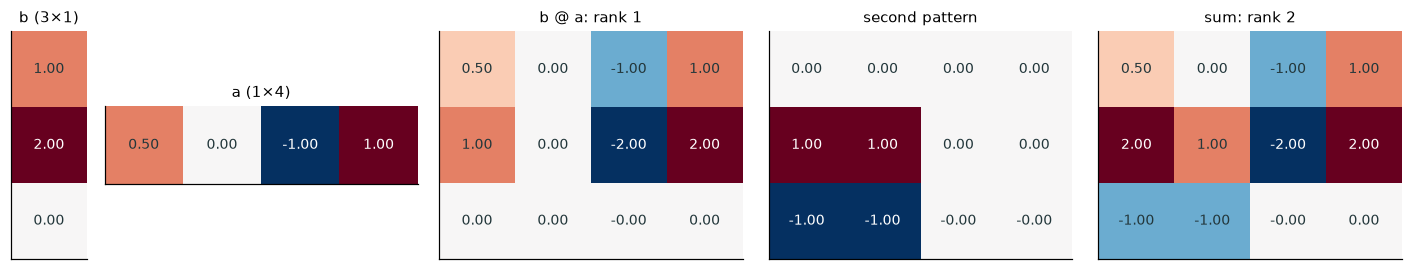

In LoRA, B holds 16 such columns and A holds 16 such rows: ΔW is the sum of 16 patterns.


In [22]:
b1 = torch.tensor([[1.0], [2.0], [0.0]])
a1 = torch.tensor([[0.5, 0.0, -1.0, 1.0]])
b2 = torch.tensor([[0.0], [1.0], [-1.0]])
a2 = torch.tensor([[1.0, 1.0, 0.0, 0.0]])
fig, axes = plt.subplots(1, 5, figsize=(13, 2.4), gridspec_kw={"width_ratios": [1, 4, 4, 4, 4]})
grid(axes[0], b1, "b (3×1)")
grid(axes[1], a1, "a (1×4)")
grid(axes[2], b1 @ a1, "b @ a: rank 1")
grid(axes[3], b2 @ a2, "second pattern")
grid(axes[4], b1 @ a1 + b2 @ a2, "sum: rank 2")
plt.tight_layout(); plt.show()
print("In LoRA, B holds 16 such columns and A holds 16 such rows: ΔW is the sum of 16 patterns.")

## E3. What "wraps every layer" means

`PEFT` is the library that adds LoRA. It goes through the model's list of named parts.
For each part whose name ends in one of `target_modules` (`q_proj`, `k_proj`, …), it **replaces** that linear layer with a slightly bigger one:

```
before:   y = x @ Wᵀ + b
after:    y = x @ Wᵀ + b   +   s · (x @ Aᵀ) @ Bᵀ
              └── frozen ──┘      └─ trained ─┘
```

- `x @ Aᵀ` squeezes 896 numbers to 16
- `@ Bᵀ` spreads the 16 back out to 896
- The original `W` is never touched during training. Only `A` and `B` learn.

Norms and the embedding table are not linear layers named like that, so LoRA leaves them alone.
Below: every named part of layer 0, and which ones LoRA picks.

In [23]:
for name, mod in hf.model.layers[0].named_modules():
    if name:
        hit = name.split(".")[-1] in MODULES
        print(f"{'LoRA → ' if hit else '        '}{name:<28} {type(mod).__name__}")

        self_attn                    Qwen2Attention
LoRA → self_attn.q_proj             Linear
LoRA → self_attn.k_proj             Linear
LoRA → self_attn.v_proj             Linear
LoRA → self_attn.o_proj             Linear
        mlp                          Qwen2MLP
LoRA → mlp.gate_proj                Linear
LoRA → mlp.up_proj                  Linear
LoRA → mlp.down_proj                Linear
        mlp.act_fn                   SiLUActivation
        input_layernorm              Qwen2RMSNorm
        post_attention_layernorm     Qwen2RMSNorm


The same thing in 10 lines of code. At the start `B` is all zeros, so the wrapped layer gives **exactly** the old output.
Training then moves `A` and `B` away from their starting values.

In [24]:
class LoRALinear(torch.nn.Module):
    def __init__(self, linear, r=16, alpha=32):
        super().__init__()
        self.linear = linear                                                      # holds W and b, frozen
        self.A = torch.nn.Parameter(torch.randn(r, linear.in_features) * 0.01)   # random start
        self.B = torch.nn.Parameter(torch.zeros(linear.out_features, r))         # zero start
        self.s = alpha / r
    def forward(self, x):
        return self.linear(x) + self.s * (x @ self.A.T) @ self.B.T

wrapped = LoRALinear(hf.model.layers[0].self_attn.q_proj)
with torch.no_grad():
    same = torch.equal(wrapped(a), hf.model.layers[0].self_attn.q_proj(a))
print("output identical at the start (B = 0):", same)

output identical at the start (B = 0): True


## E4. Where the trained numbers live

| Folder | Contents |
|---|---|
| `adapter/adapter_model.safetensors` | Only `A` and `B`, for all 168 (24 layers x 7 proj lora components) targets (336 tensors (2 matrices A and B per each lora component)) |
| `merged/model.safetensors` | `W + s·B@A` already added up, saved as a normal full model in bf16 |

`merged/` is what eval and merging use. `adapter/` is the cleaner record of what training learned.

---
# Part F · Which LoRA weights changed, for each specialist

Two facts to keep in mind:
- `B` started at **exactly 0**. Every non-zero number in `B` was learned by GRPO.
- `A` started **random**, and those starting values were not saved. So for `A` only the final state is visible.
  That is why the analysis below focuses on `B` and on `ΔW = s·B@A` (which is also exactly 0 at the start).

In [25]:
avail = [t for t in TASKS if (SPEC[t] / "adapter" / "adapter_model.safetensors").exists()]
print("specialists found:", avail)
ADP, SCALE = {}, {}
for t in avail:
    ADP[t] = safe_open(SPEC[t] / "adapter" / "adapter_model.safetensors", "pt")
    ac = json.loads((SPEC[t] / "adapter" / "adapter_config.json").read_text())
    SCALE[t] = ac["lora_alpha"] / ac["r"]

def AB(t, l, mod):
    p = f"base_model.model.model.layers.{l}.{sub(mod)}.{mod}"
    return ADP[t].get_tensor(p + ".lora_A.weight").float(), ADP[t].get_tensor(p + ".lora_B.weight").float()

def dW(t, l, mod):
    A_, B_ = AB(t, l, mod)
    return SCALE[t] * B_ @ A_

specialists found: ['gsm8k', 'logic', 'code']


## F1. How much did `B` move from zero?

Distribution of all `B` numbers per specialist (log scale of their size). Further right = bigger learned changes.

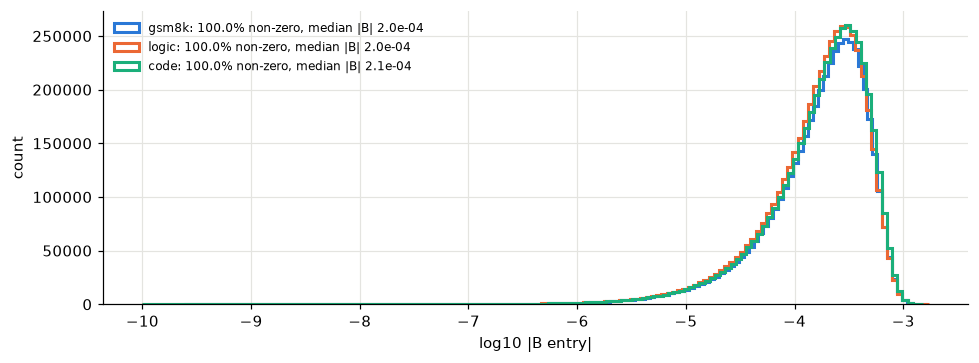

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for t in avail:
    allB = torch.cat([AB(t, l, m_)[1].flatten() for l in range(N_LAYERS) for m_ in MODULES])
    ax.hist(np.log10(allB.abs().clamp(min=1e-10).numpy()), bins=150, histtype="step", lw=2, color=C_TASK[t],
            label=f"{t}: {(allB != 0).float().mean():.1%} non-zero, median |B| {allB.abs().median():.1e}")
ax.set_xlabel("log10 |B entry|"); ax.set_ylabel("count"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## F2. Where in the model did each specialist change things?

One square per (layer, matrix). Colour = size of the change relative to the original matrix, `|ΔW| / |W|`.
Same colour scale for all specialists, so you can compare them.

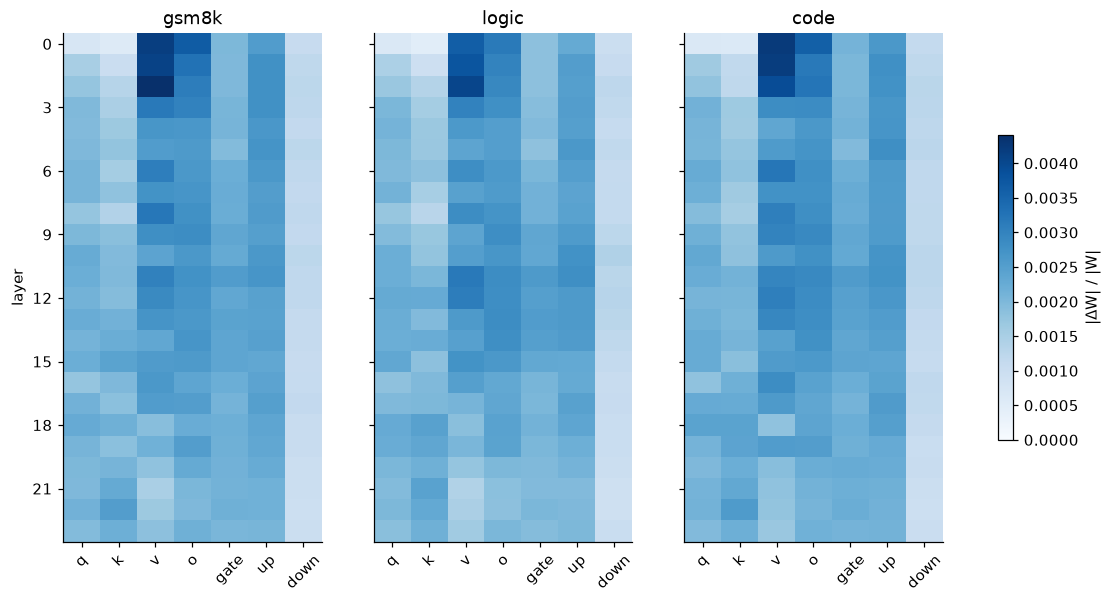

In [27]:
WN = {(l, m_): base.get(wname(l, m_)).float().norm().item() for l in range(N_LAYERS) for m_ in MODULES}
REL = {t: np.array([[dW(t, l, m_).norm().item() / WN[(l, m_)] for m_ in MODULES] for l in range(N_LAYERS)]) for t in avail}
vmax = max(r_.max() for r_ in REL.values())
fig, axes = plt.subplots(1, len(avail), figsize=(4.3 * len(avail), 6), sharey=True)
for ax, t in zip(np.atleast_1d(axes), avail):
    im = ax.imshow(REL[t], cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(MODULES)), [m_.replace("_proj", "") for m_ in MODULES], rotation=45)
    ax.set_yticks(range(0, N_LAYERS, max(1, N_LAYERS // 8)))
    ax.set_title(f"{t}"); ax.grid(False)
np.atleast_1d(axes)[0].set_ylabel("layer")
fig.colorbar(im, ax=axes, shrink=0.6, label="|ΔW| / |W|"); plt.show()

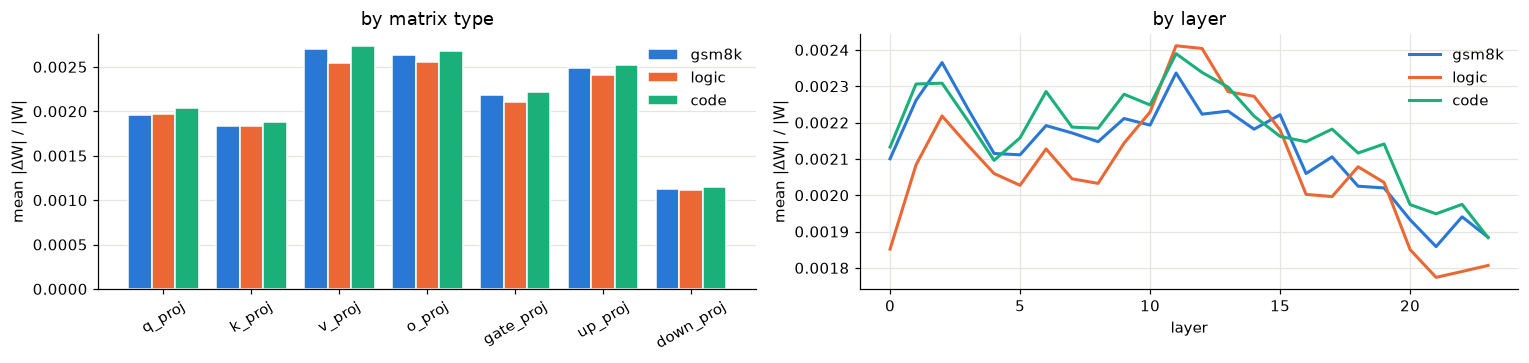

In [28]:
x_ = np.arange(len(MODULES)); w_ = 0.8 / max(len(avail), 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
for j, t in enumerate(avail):
    axes[0].bar(x_ + (j - (len(avail) - 1) / 2) * w_, REL[t].mean(0), w_, color=C_TASK[t], label=t, edgecolor="white")
    axes[1].plot(range(N_LAYERS), REL[t].mean(1), color=C_TASK[t], lw=2, label=t)
axes[0].set_xticks(x_, MODULES, rotation=30); axes[0].set_ylabel("mean |ΔW| / |W|"); axes[0].grid(axis="x", visible=False)
axes[1].set_xlabel("layer"); axes[1].set_ylabel("mean |ΔW| / |W|")
axes[0].set_title("by matrix type"); axes[1].set_title("by layer")
for ax in axes: ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## F3. Zoom into one matrix

Pick a layer and a matrix. Which **output features** (rows of ΔW) and **input features** (columns of ΔW) did each specialist change most?
If two specialists' curves peak in the same places, they changed the same part of the matrix, which is where merging can clash.

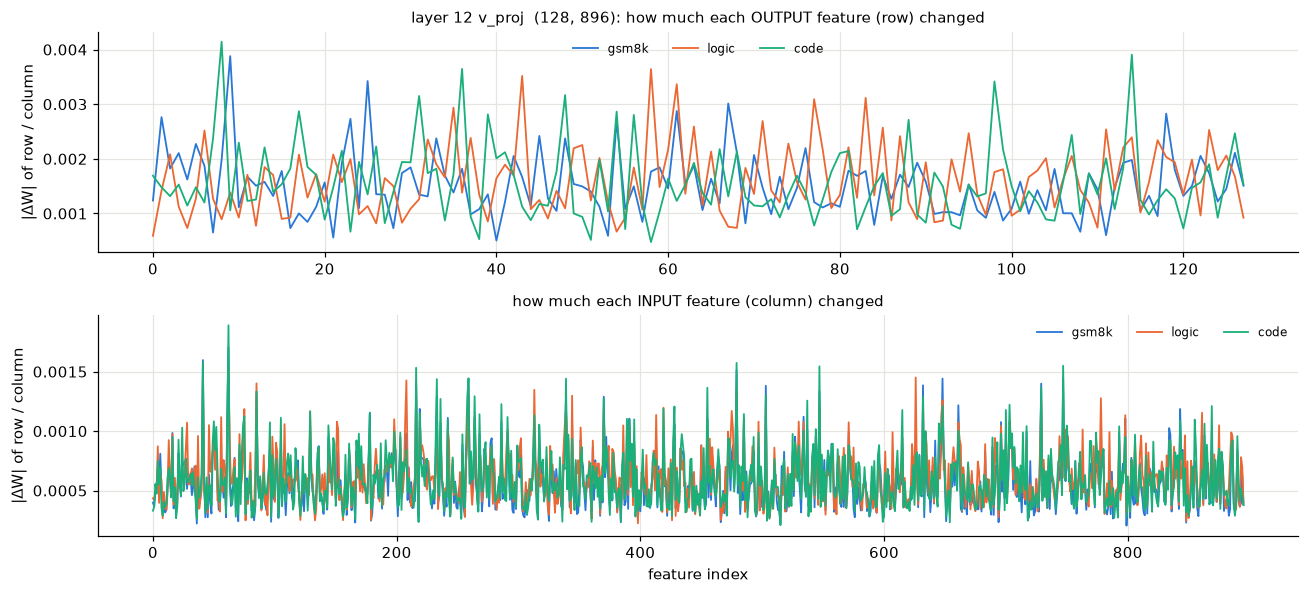

In [29]:
LZ, MZ = N_LAYERS // 2, "v_proj"           # change these
Wz = base.get(wname(LZ, MZ)).float()
DZ = {t: dW(t, LZ, MZ) for t in avail}
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5))
for t in avail:
    axes[0].plot(DZ[t].norm(dim=1), color=C_TASK[t], lw=1.2, label=t)
    axes[1].plot(DZ[t].norm(dim=0), color=C_TASK[t], lw=1.2, label=t)
axes[0].set_title(f"layer {LZ} {MZ}  {tuple(Wz.shape)}: how much each OUTPUT feature (row) changed", fontsize=10)
axes[1].set_title("how much each INPUT feature (column) changed", fontsize=10)
axes[1].set_xlabel("feature index")
for ax in axes: ax.set_ylabel("|ΔW| of row / column"); ax.legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

### The actual numbers: base W, change, new W

A 24 × 24 corner of the chosen matrix. First column: the original weights. Then each specialist's ΔW, on its own colour scale.

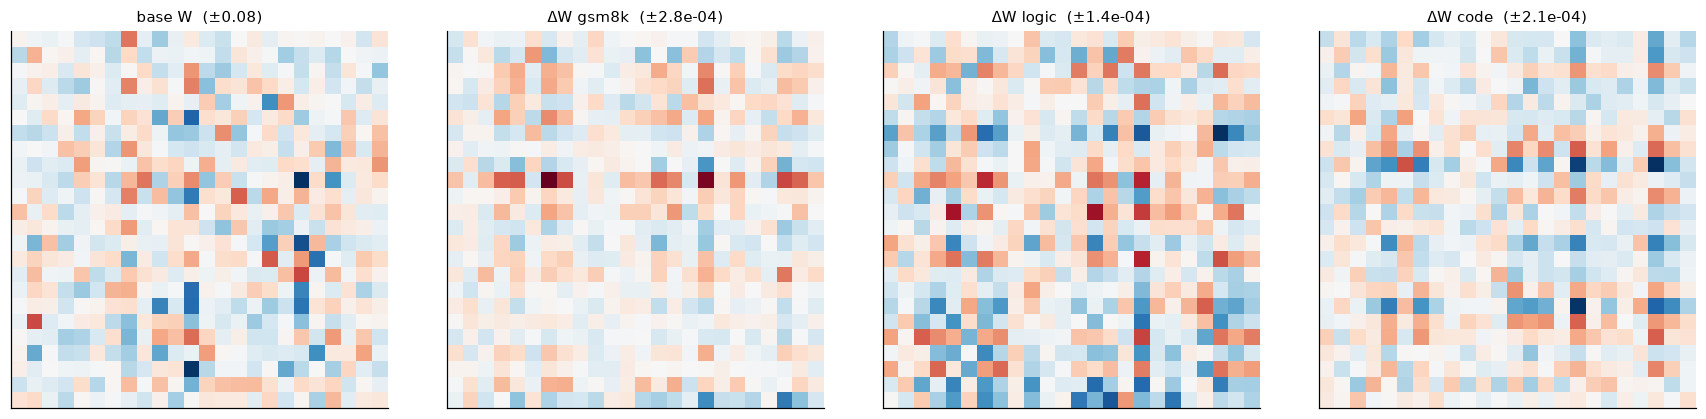

In [30]:
n_ = 24
fig, axes = plt.subplots(1, 1 + len(avail), figsize=(4 * (1 + len(avail)), 3.8))
v_ = Wz[:n_, :n_].abs().max().item()
axes[0].imshow(Wz[:n_, :n_], cmap="RdBu_r", vmin=-v_, vmax=v_); axes[0].set_title(f"base W  (±{v_:.2f})", fontsize=10)
for ax, t in zip(axes[1:], avail):
    d_ = DZ[t][:n_, :n_]; v2 = d_.abs().max().item()
    ax.imshow(d_, cmap="RdBu_r", vmin=-v2, vmax=v2); ax.set_title(f"ΔW {t}  (±{v2:.1e})", fontsize=10)
for ax in axes: ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### The 10 most-changed weights for each specialist

`also top-1% in` lists the other specialists that changed this same weight a lot.

In [31]:
import pandas as pd
top1 = {t: set(DZ[t].abs().flatten().topk(max(1, DZ[t].numel() // 100)).indices.tolist()) for t in avail}
for t in avail:
    flat = DZ[t].flatten()
    idx = flat.abs().topk(10).indices
    rows_ = []
    for i_ in idx.tolist():
        r_, c_ = divmod(i_, Wz.shape[1])
        rows_.append({"row": r_, "col": c_, "base W": Wz[r_, c_].item(), "ΔW": flat[i_].item(),
                      "new W": Wz[r_, c_].item() + flat[i_].item(),
                      "change %": 100 * flat[i_].item() / (abs(Wz[r_, c_].item()) + 1e-12),
                      "also top-1% in": ", ".join(o for o in avail if o != t and i_ in top1[o]) or "-"})
    print(f"\n{t} specialist, layer {LZ} {MZ}")
    display(pd.DataFrame(rows_).style.format({"base W": "{:+.5f}", "ΔW": "{:+.5f}", "new W": "{:+.5f}", "change %": "{:+.1f}"}))


gsm8k specialist, layer 12 v_proj


,row,col,base W,ΔW,new W,change %,also top-1% in
0,9,41,-0.04028,+0.00046,-0.03983,+1.1,logic
1,9,62,+0.00279,+0.00045,+0.00324,+16.0,-
2,9,259,+0.02246,+0.00043,+0.02289,+1.9,-
3,9,370,+0.01154,+0.00041,+0.01194,+3.5,-
4,25,62,-0.00191,+0.00040,-0.00150,+21.2,-
5,9,479,+0.01208,-0.00040,+0.01168,-3.3,-
6,9,648,-0.00610,-0.00040,-0.00650,-6.5,-
7,9,339,-0.00088,-0.00039,-0.00126,-44.0,-
8,9,729,+0.02600,+0.00038,+0.02639,+1.5,-
9,25,41,+0.00386,+0.00038,+0.00424,+9.8,-



logic specialist, layer 12 v_proj


,row,col,base W,ΔW,new W,change %,also top-1% in
0,43,62,+0.00510,+0.00044,+0.00553,+8.6,-
1,43,41,+0.01758,+0.00043,+0.01801,+2.5,-
2,58,62,-0.00072,-0.00042,-0.00114,-57.6,gsm8k
3,43,479,-0.00111,-0.00039,-0.00149,-35.0,-
4,58,41,-0.03174,-0.00037,-0.03211,-1.2,gsm8k
5,58,216,+0.00171,+0.00037,+0.00208,+21.6,-
6,61,62,+0.00269,+0.00036,+0.00305,+13.5,gsm8k
7,61,41,+0.00421,+0.00036,+0.00457,+8.5,gsm8k
8,43,370,+0.00192,+0.00036,+0.00228,+18.6,-
9,43,259,+0.00513,+0.00035,+0.00548,+6.9,-



code specialist, layer 12 v_proj


,row,col,base W,ΔW,new W,change %,also top-1% in
0,8,62,-0.00162,-0.00046,-0.00208,-28.7,gsm8k
1,114,62,+0.00316,-0.00046,+0.00270,-14.4,-
2,36,62,-0.00050,-0.00044,-0.00094,-87.9,gsm8k
3,8,747,-0.00867,+0.00042,-0.00824,+4.9,-
4,8,216,-0.03101,+0.00042,-0.03059,+1.4,gsm8k
5,8,547,+0.00754,-0.00041,+0.00713,-5.5,gsm8k
6,8,479,-0.02612,+0.00040,-0.02573,+1.5,gsm8k
7,114,233,+0.00897,-0.00040,+0.00858,-4.4,-
8,114,547,-0.00076,-0.00039,-0.00115,-52.3,-
9,114,729,+0.00867,-0.00037,+0.00829,-4.3,-


### One changed weight, traced back to `A` and `B`

ΔW[i, j] = s · Σₖ B[i, k] · A[k, j]: a sum of 16 products, one per LoRA pattern.

In [32]:
t = avail[0] if avail else None                 # change to "logic" or "code"
A_, B_ = AB(t, LZ, MZ)
i_, j_ = divmod(int(DZ[t].abs().argmax()), Wz.shape[1])
terms = SCALE[t] * B_[i_] * A_[:, j_]
print(f"{t}, layer {LZ} {MZ}, weight [{i_}, {j_}]\n")
print(f"{'k':>3}{'B[i,k]':>12}{'A[k,j]':>12}{'s·B·A':>12}")
for k_ in range(len(terms)):
    print(f"{k_:>3}{B_[i_, k_].item():>12.5f}{A_[k_, j_].item():>12.5f}{terms[k_].item():>12.6f}")
print(f"{'sum':>27}{terms.sum().item():>12.6f}\n")
print(f"base W        {Wz[i_, j_].item():+.6f}")
print(f"base W + ΔW   {(Wz[i_, j_] + terms.sum()).item():+.6f}")
print(f"saved merged/ {LazyWeights(SPEC[t] / 'merged').get(wname(LZ, MZ))[i_, j_].float().item():+.6f}   (bf16 rounding)")

gsm8k, layer 12 v_proj, weight [9, 41]

  k      B[i,k]      A[k,j]       s·B·A
  0     0.00091     0.01633    0.000030
  1    -0.00110    -0.02720    0.000060
  2     0.00032    -0.00901   -0.000006
  3     0.00091     0.01325    0.000024
  4     0.00101     0.03017    0.000061
  5    -0.00090    -0.00126    0.000002
  6     0.00062    -0.00649   -0.000008
  7     0.00052     0.03285    0.000034
  8    -0.00092    -0.02285    0.000042
  9    -0.00008    -0.02044    0.000003
 10    -0.00004    -0.00395    0.000000
 11     0.00069     0.02831    0.000039
 12    -0.00104    -0.03303    0.000069
 13     0.00091     0.02650    0.000048
 14     0.00097     0.01650    0.000032
 15     0.00084     0.01621    0.000027
                        sum    0.000458

base W        -0.040283
base W + ΔW   -0.039825
saved merged/ -0.039795   (bf16 rounding)


## F4. Do the specialists change the same weights?

For every one of the 168 matrices: take each specialist's top 1% most-changed weights, and measure how many are shared between two specialists.
If changes were placed at random, the overlap would be about 1%. Much higher = they compete for the same weights.

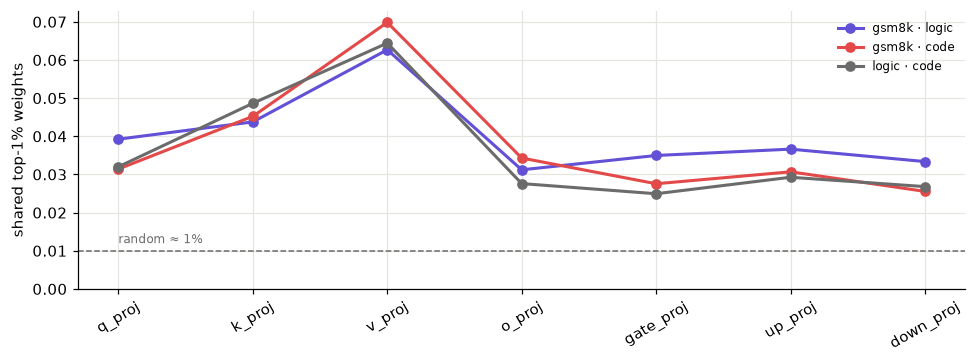

In [33]:
pairs = [(avail[i], avail[j]) for i in range(len(avail)) for j in range(i + 1, len(avail))]
OV = {p_: np.zeros((N_LAYERS, len(MODULES))) for p_ in pairs}
for l in range(N_LAYERS):
    for jm, m_ in enumerate(MODULES):
        sets = {}
        for t_ in avail:
            d_ = dW(t_, l, m_).abs().flatten()
            sets[t_] = set(d_.topk(max(1, d_.numel() // 100)).indices.tolist())
        for (p1, p2) in pairs:
            OV[(p1, p2)][l, jm] = len(sets[p1] & sets[p2]) / len(sets[p1])
fig, ax = plt.subplots(figsize=(9, 3.4))
C_PAIR = ["#6250d6", "#e34948", "#6b6b6b"]
for (p_, col) in zip(pairs, C_PAIR):
    ax.plot(range(len(MODULES)), OV[p_].mean(0), color=col, lw=2, marker="o", ms=6, label=f"{p_[0]} · {p_[1]}")
ax.axhline(0.01, color="#6b6b6b", ls="--", lw=1); ax.text(0, 0.012, "random ≈ 1%", color="#6b6b6b", fontsize=8)
ax.set_xticks(range(len(MODULES)), MODULES, rotation=30); ax.set_ylabel("shared top-1% weights")
ax.legend(frameon=False, fontsize=8); ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

## F5. What the changes do to a prediction

The same three prompts through base and each specialist. Top 5 next-token guesses.
This is where tiny weight changes show up as different behaviour.

In [ ]:
PROMPTS = {"maths": "Tom has 3 boxes with 4 apples each. He eats 2 apples. Apples left:",
           "logic": TEXT,
           "code": "def is_even(n):\n    return"}
def top5(model, text):
    ids_, _ = encode(text)
    with torch.no_grad():
        pr = model(ids_).logits[0, -1].softmax(-1)
    v_, i_ = pr.topk(5)
    return "  ".join(f"{decode(k_)!r} {p_:.0%}" for p_, k_ in zip(v_.tolist(), i_.tolist()))

results = {"base": {k_: top5(hf, p_) for k_, p_ in PROMPTS.items()}}
for t in avail:
    mdl = AutoModelForCausalLM.from_pretrained(SPEC[t] / "merged", dtype=torch.float32).eval()
    results[t] = {k_: top5(mdl, p_) for k_, p_ in PROMPTS.items()}
    del mdl
for k_, p_ in PROMPTS.items():
    print(f"\n{k_.upper()}: {p_!r}")
    for who, r_ in results.items():
        print(f"   {who:<6} {r_[k_]}")

Loading weights:   1%|          | 3/290 [00:01<02:27,  1.95it/s]